# 03. 功能富集

本 notebook 检验 environmental association signals 在位点和基因层级的富集，并实施审稿中要求的条件生物学背景、匹配对照、LD-aware analyses 以及 MAF/LoF sensitivity analyses。


In [1]:
import os
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

data_dir = os.path.join(os.getcwd(), "data")
source_dir = os.path.join(data_dir, "source")
results_dir = os.path.join(data_dir, "results")
run_dir = os.path.join(os.getcwd(), "run")

enrich_dir = os.path.join(results_dir, "enrichment")
os.makedirs(enrich_dir, exist_ok=True)

载入contexts设定

In [2]:
import json
import gzip

datasets = {
    'genome': pd.read_hdf(os.path.join(data_dir, "results", "site_contexts.genome.maf0.05.h5"), key="df"), # All variants with MAF >= 0.05
    'cds': pd.read_hdf(os.path.join(data_dir, "results", "site_contexts.cds.maf0.01.h5"), key="df"), # All variants in coding regions with MAF >= 0.01
    'gene': pd.read_hdf(os.path.join(data_dir, "results", "gene_contexts.h5"), key="df") # All genes
}

datasets['genome']['genome'] = True
datasets['cds']['cds'] = True
datasets['gene']['gene'] = True

contexts_settings_json_file = os.path.join(os.getcwd(), "config", "contexts_settings.json")
with open(contexts_settings_json_file, "r") as f:
    contexts_settings = json.load(f)

载入envGWAS结果

In [3]:
import numpy as np
from src.ld import calculate_ld_matrix

# genome site level envGWAS results
env_id_list = ["bio18", "gsl", "al", "striga"]
env_metadata_df = pd.read_csv(os.path.join(data_dir, "source", "envir_metadata.csv"))
genome_vcf_file = os.path.join(data_dir, "results", "landraces_qc_miss0.5_maf0.05_het0.05.vcf.gz")
cds_vcf_file = os.path.join(data_dir, "results", "landraces_cds_miss0.5_maf0.01_het0.05.vcf.gz")
ld_window_size = 15000
min_r2 = 0.5
threads = 40

ld_dict = {
    'genome': calculate_ld_matrix(datasets['genome'], genome_vcf_file, ld_window_size=ld_window_size, min_r2=min_r2, pool_num=threads),
    'cds': calculate_ld_matrix(datasets['cds'], cds_vcf_file, ld_window_size=ld_window_size, min_r2=min_r2, pool_num=threads)
}

for env_id in env_id_list:
    env_df = pd.read_hdf(os.path.join(data_dir, "results", "gwas", env_id, f"{env_id}.gemma", f"{env_id}.gemma.gwas_df.h5"), key="df")
    env_df = env_df[['ID', 'P_WALD']]
    env_df = env_df.rename(columns={'P_WALD': env_id})
    env_df[env_id] = -np.log10(env_df[env_id])
    datasets['genome'] = datasets['genome'].merge(env_df, on='ID', how='left')
 
    env_cds_df = pd.read_hdf(os.path.join(data_dir, "results", "gwas", env_id, f"{env_id}_cds.gemma", f"{env_id}_cds.gemma.gwas_df.h5"), key="df")
    env_cds_df = env_cds_df[['ID', 'P_WALD']]
    env_cds_df = env_cds_df.rename(columns={'P_WALD': env_id})
    env_cds_df[env_id] = -np.log10(env_cds_df[env_id])
    datasets['cds'] = datasets['cds'].merge(env_cds_df, on='ID', how='left')
    
    env_gene_df = pd.read_hdf(os.path.join(data_dir, "results", "gwas", env_id, f"{env_id}.magma", f"{env_id}.magma.gwas_df.h5"), key="df")
    env_gene_df = env_gene_df[['ID', 'P_VALUE']]
    env_gene_df = env_gene_df.rename(columns={'P_VALUE': env_id})
    env_gene_df[env_id] = -np.log10(env_gene_df[env_id])
    datasets['gene'] = datasets['gene'].merge(env_gene_df, on='ID', how='left')

LD pairs: 6452567/6452567 (100.0%) | elapsed 190.9s
LD pairs: 408830/408830 (100.0%) | elapsed 13.4s


载入contrasts设定

In [4]:
contrasts_settings_json_file = os.path.join(os.getcwd(), "config", "contrasts_settings.json")
with open(contrasts_settings_json_file, "r") as f:
    contrasts_settings = json.load(f)

## 1. Genomic compartments

### 1.1 genic_2kb_vs_genome

In [5]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "genic_2kb_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: genic_2kb_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: genic_2kb
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast genic_2kb_vs_genome, skipping.
LD overlap results already exist for contrast genic_2kb_vs_genome. Skipping calculation.


Enrichment results for contrast: genic_2kb_vs_genome


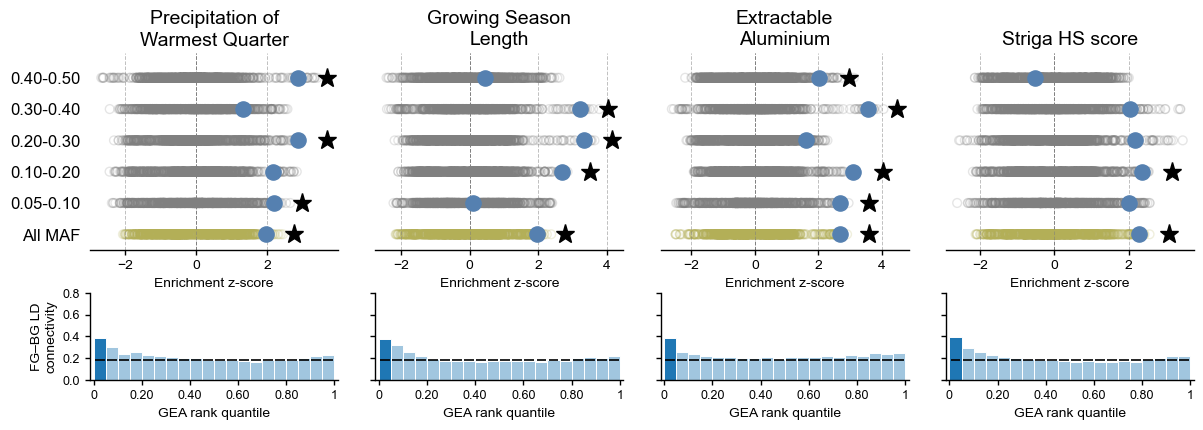

In [6]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 1.2 TE_vs_genome

In [7]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "TE_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)    

Running enrichment for contrast: TE_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: TE
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast TE_vs_genome, skipping.
LD overlap results already exist for contrast TE_vs_genome. Skipping calculation.


Enrichment results for contrast: TE_vs_genome


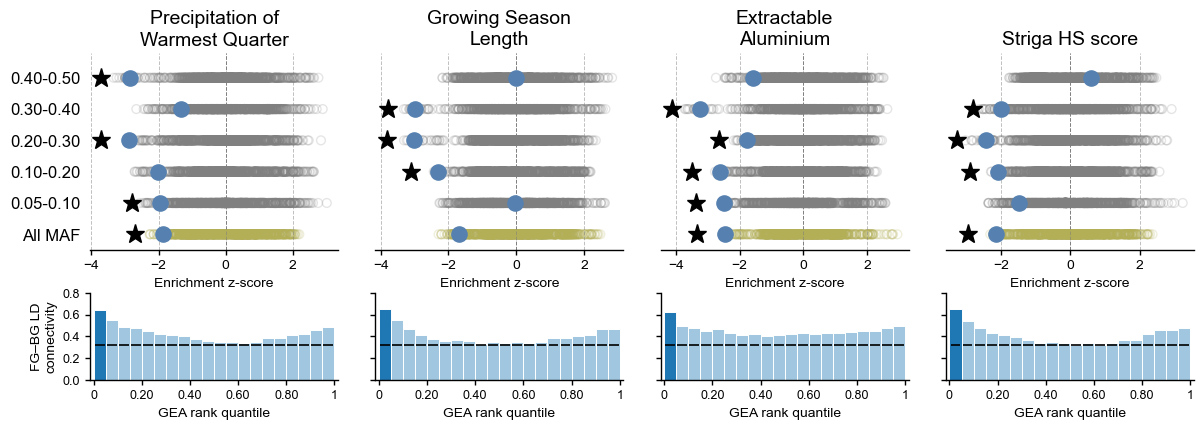

In [8]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 1.3 other_intergenic_vs_genome

In [9]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "other_intergenic_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)    

Running enrichment for contrast: other_intergenic_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: other_intergenic
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast other_intergenic_vs_genome, skipping.
LD overlap results already exist for contrast other_intergenic_vs_genome. Skipping calculation.


Enrichment results for contrast: other_intergenic_vs_genome


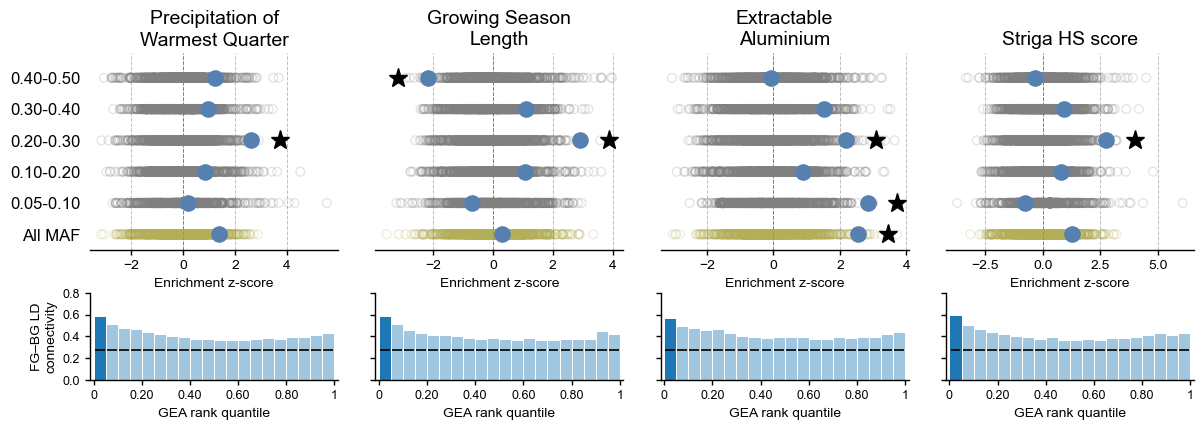

In [10]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

## 2. Gene Structure

### 2.1 在基因区内部比较

#### 2.1.1 upstream_2kb_vs_genic

In [11]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "upstream_2kb_vs_genic"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: upstream_2kb_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: upstream_2kb & genic_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast upstream_2kb_vs_genic, skipping.
LD overlap results already exist for contrast upstream_2kb_vs_genic. Skipping calculation.


Enrichment results for contrast: upstream_2kb_vs_genic


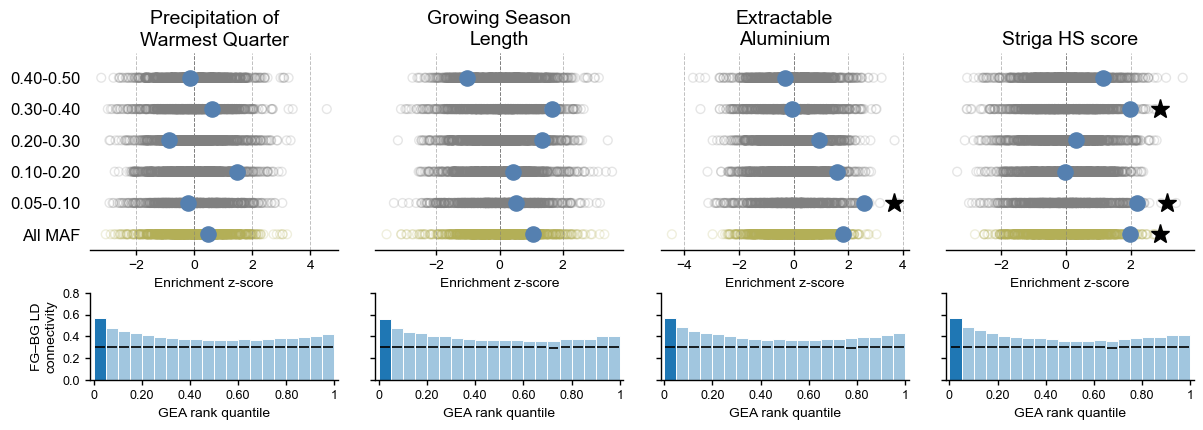

In [12]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.1.2 five_prime_UTR_vs_genic

In [13]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "five_prime_UTR_vs_genic"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: five_prime_UTR_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: five_prime_UTR & genic_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast five_prime_UTR_vs_genic, skipping.
LD overlap results already exist for contrast five_prime_UTR_vs_genic. Skipping calculation.


Enrichment results for contrast: five_prime_UTR_vs_genic


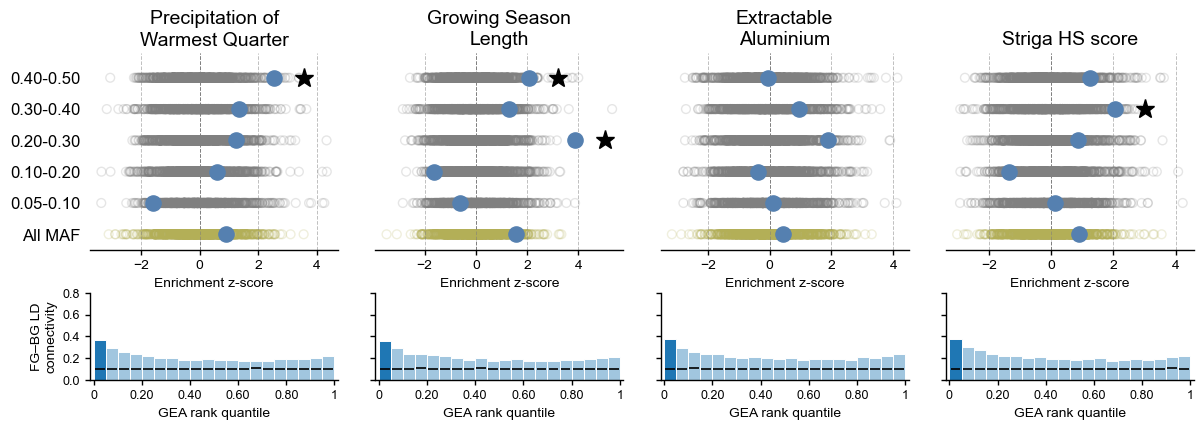

In [14]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.1.3 CDS_vs_genic

In [15]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "CDS_vs_genic"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: CDS_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: CDS & genic_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast CDS_vs_genic, skipping.
LD overlap results already exist for contrast CDS_vs_genic. Skipping calculation.


Enrichment results for contrast: CDS_vs_genic


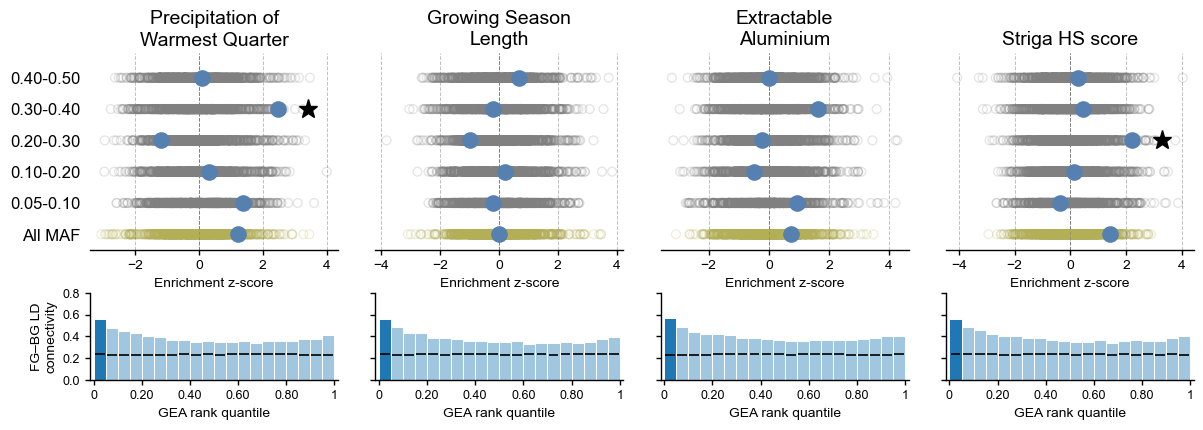

In [16]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.1.4 intron_vs_genic

In [17]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "intron_vs_genic"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: intron_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: intron & genic_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast intron_vs_genic, skipping.
LD overlap results already exist for contrast intron_vs_genic. Skipping calculation.


Enrichment results for contrast: intron_vs_genic


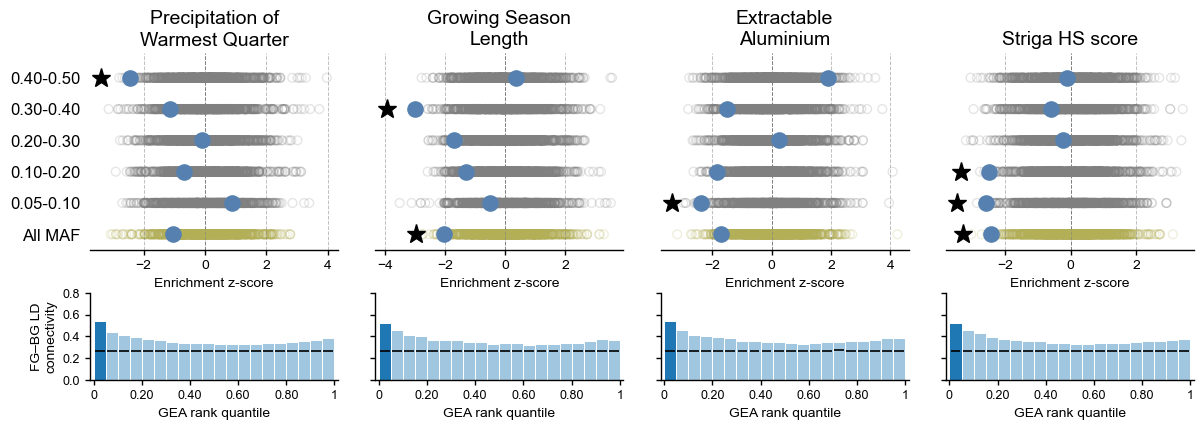

In [18]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.1.5 three_prime_UTR_vs_genic

In [19]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "three_prime_UTR_vs_genic"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: three_prime_UTR_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: three_prime_UTR & genic_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast three_prime_UTR_vs_genic, skipping.
LD overlap results already exist for contrast three_prime_UTR_vs_genic. Skipping calculation.


Enrichment results for contrast: three_prime_UTR_vs_genic


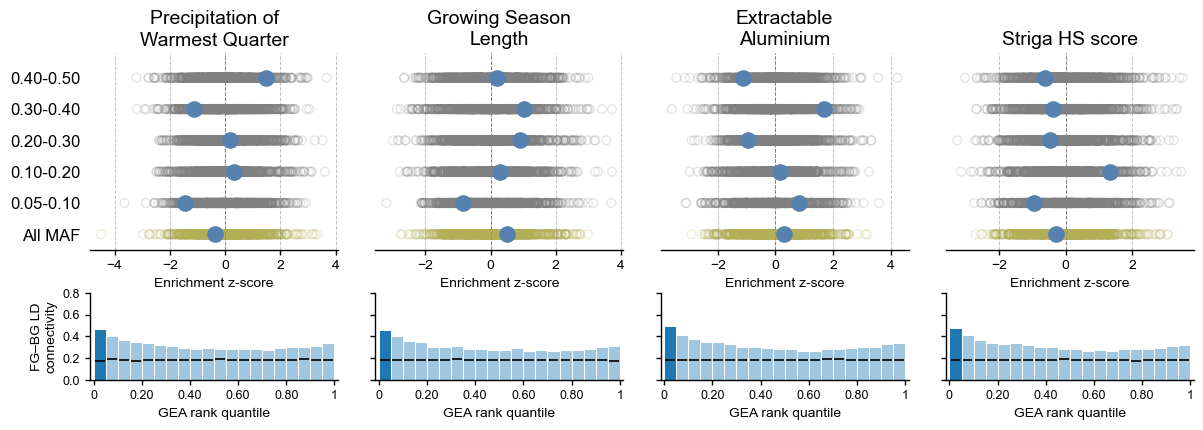

In [20]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.1.6 downstream_2kb_vs_genic

In [21]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "downstream_2kb_vs_genic"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: downstream_2kb_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: downstream_2kb & genic_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast downstream_2kb_vs_genic, skipping.
LD overlap results already exist for contrast downstream_2kb_vs_genic. Skipping calculation.


Enrichment results for contrast: downstream_2kb_vs_genic


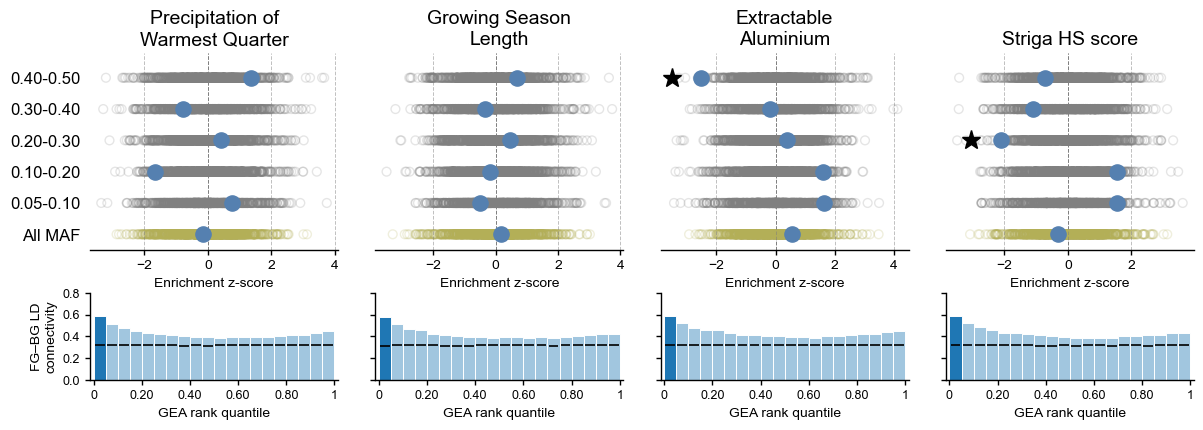

In [22]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 2.2 在基因组范围比较

#### 2.2.1 upstream_2kb_vs_genome

In [23]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "upstream_2kb_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: upstream_2kb_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: upstream_2kb
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast upstream_2kb_vs_genome, skipping.
LD overlap results already exist for contrast upstream_2kb_vs_genome. Skipping calculation.


Enrichment results for contrast: upstream_2kb_vs_genome


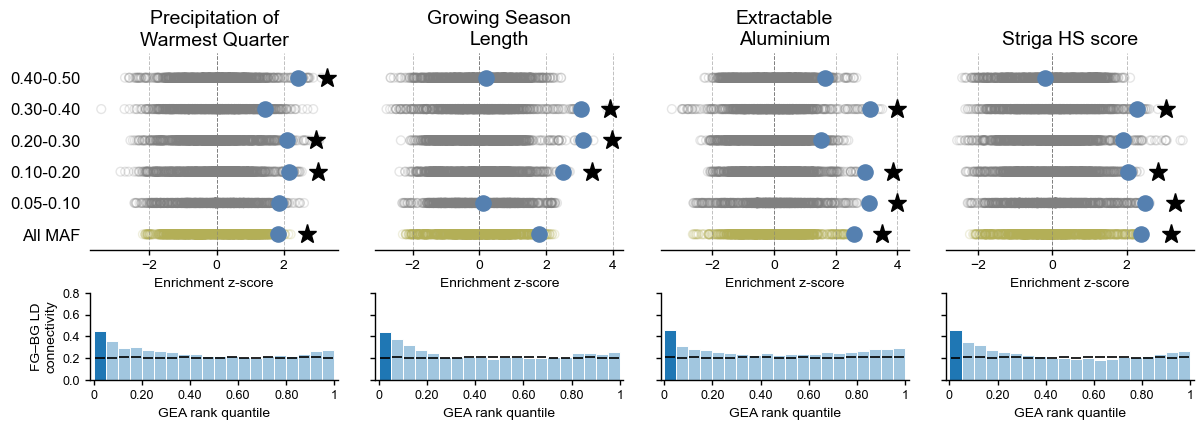

In [24]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.2.2 five_prime_UTR_vs_genome

In [25]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "five_prime_UTR_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: five_prime_UTR_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: five_prime_UTR
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast five_prime_UTR_vs_genome, skipping.
LD overlap results already exist for contrast five_prime_UTR_vs_genome. Skipping calculation.


Enrichment results for contrast: five_prime_UTR_vs_genome


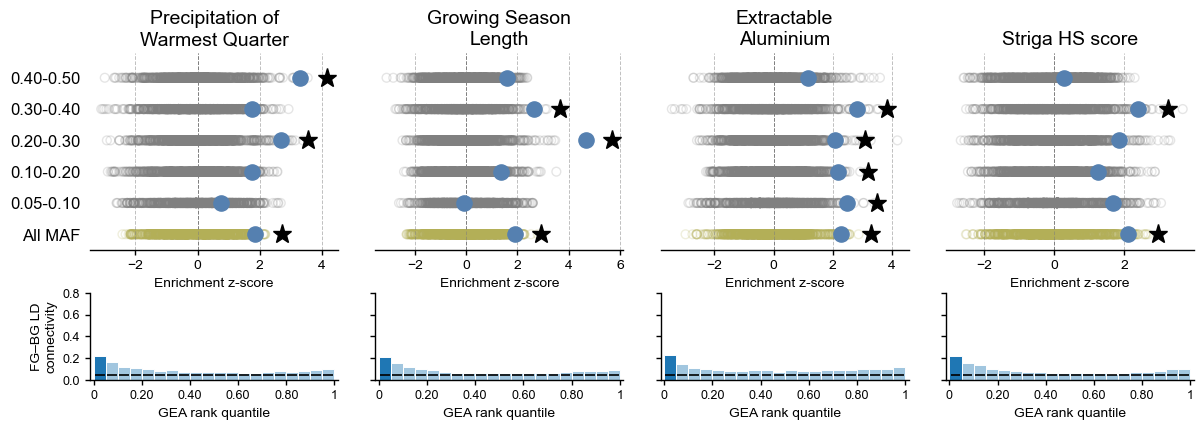

In [26]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.2.3 CDS_vs_genome

In [27]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "CDS_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: CDS_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: CDS
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast CDS_vs_genome, skipping.
LD overlap results already exist for contrast CDS_vs_genome. Skipping calculation.


Enrichment results for contrast: CDS_vs_genome


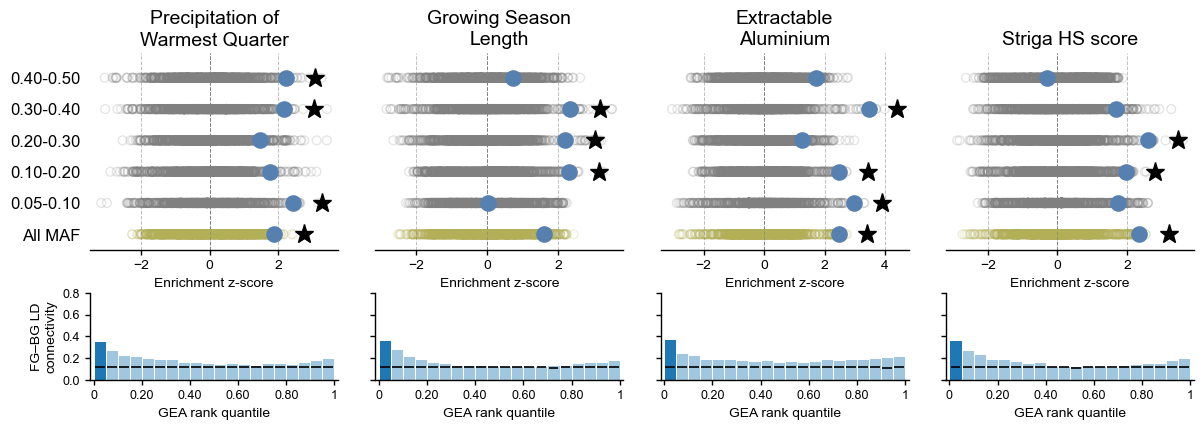

In [28]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.2.4 intron_vs_genome

In [29]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "intron_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: intron_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: intron
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast intron_vs_genome, skipping.
LD overlap results already exist for contrast intron_vs_genome. Skipping calculation.


Enrichment results for contrast: intron_vs_genome


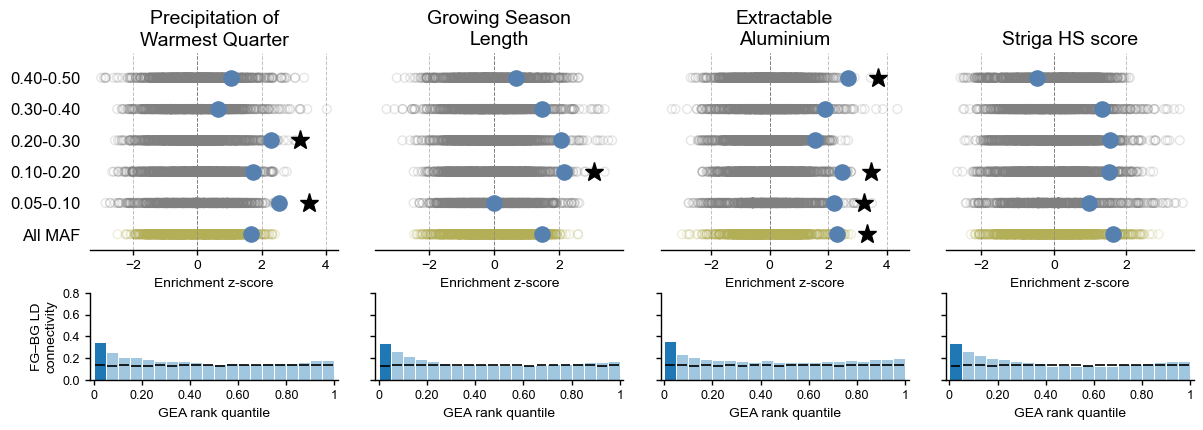

In [30]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.2.5 three_prime_UTR_vs_genome

In [31]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "three_prime_UTR_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: three_prime_UTR_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: three_prime_UTR
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast three_prime_UTR_vs_genome, skipping.
LD overlap results already exist for contrast three_prime_UTR_vs_genome. Skipping calculation.


Enrichment results for contrast: three_prime_UTR_vs_genome


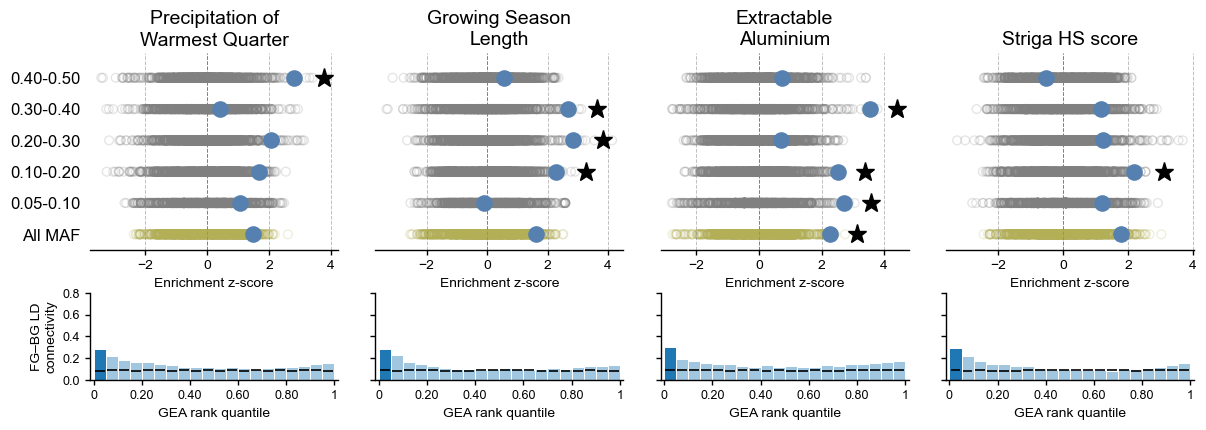

In [32]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.2.6 downstream_2kb_vs_genome

In [33]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "downstream_2kb_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: downstream_2kb_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: downstream_2kb
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast downstream_2kb_vs_genome, skipping.
LD overlap results already exist for contrast downstream_2kb_vs_genome. Skipping calculation.


Enrichment results for contrast: downstream_2kb_vs_genome


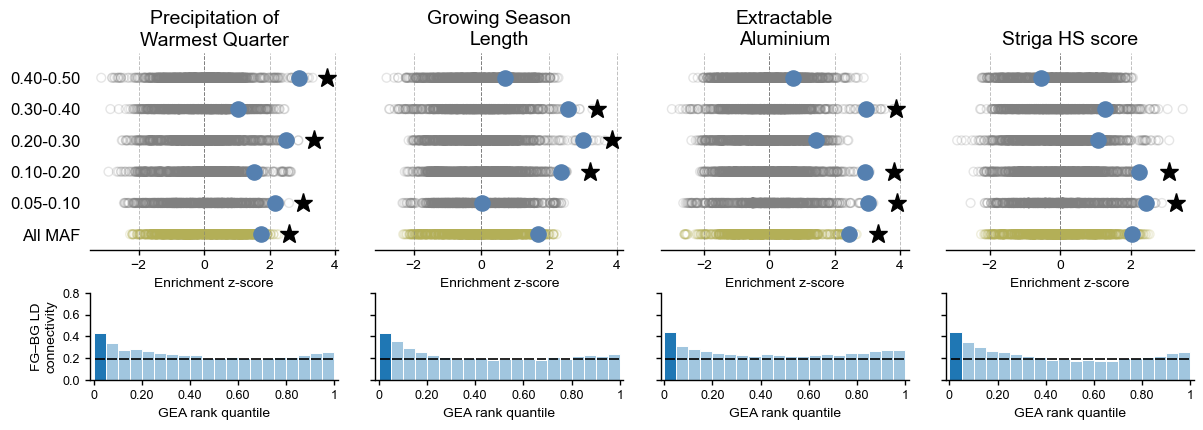

In [34]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 2.3 在CDS中的比较

#### 2.3.1 missense_vs_CDS

In [35]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "missense_vs_CDS"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: missense_vs_CDS
Using dataset: cds
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: `missense_cds_0.01`
  Background set: cds
  MAF stratify: ['all', 'maf_0.01_0.03_cds_0.01', 'maf_0.03_0.05_cds_0.01', 'maf_0.05_0.1_cds_0.01', 'maf_0.1_0.2_cds_0.01', 'maf_0.2_0.3_cds_0.01', 'maf_0.3_0.4_cds_0.01', 'maf_0.4_0.5_cds_0.01']
Enrichment results already exist for contrast missense_vs_CDS, skipping.
LD overlap results already exist for contrast missense_vs_CDS. Skipping calculation.


Enrichment results for contrast: missense_vs_CDS


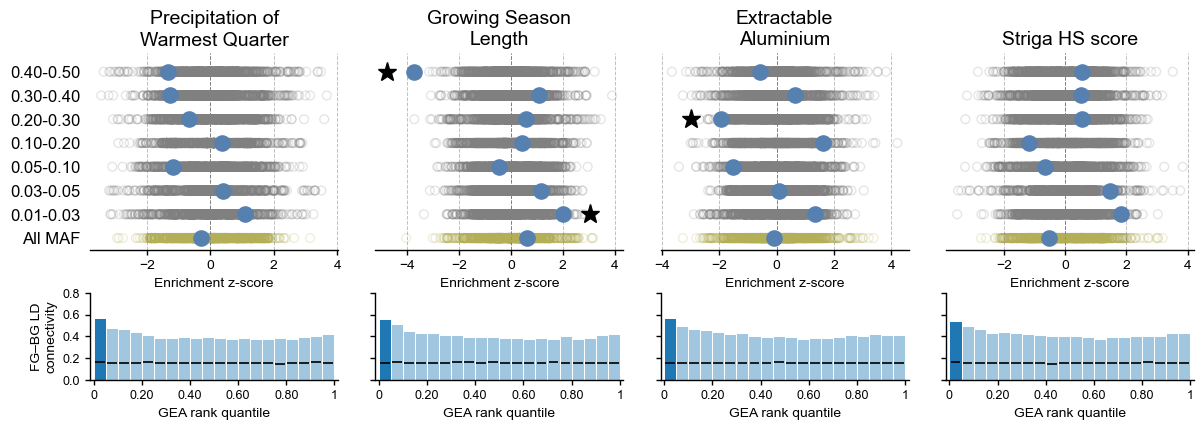

In [36]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.01_0.03_cds_0.01', '0.01-0.03'],
    ['maf_0.03_0.05_cds_0.01', '0.03-0.05'],
    ['maf_0.05_0.1_cds_0.01', '0.05-0.10'],
    ['maf_0.1_0.2_cds_0.01', '0.10-0.20'],
    ['maf_0.2_0.3_cds_0.01', '0.20-0.30'],
    ['maf_0.3_0.4_cds_0.01', '0.30-0.40'],
    ['maf_0.4_0.5_cds_0.01', '0.40-0.50']
]

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.3.2 synonymous_vs_CDS

In [37]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "synonymous_vs_CDS"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: synonymous_vs_CDS
Using dataset: cds
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: `synonymous_cds_0.01`
  Background set: cds
  MAF stratify: ['all', 'maf_0.01_0.03_cds_0.01', 'maf_0.03_0.05_cds_0.01', 'maf_0.05_0.1_cds_0.01', 'maf_0.1_0.2_cds_0.01', 'maf_0.2_0.3_cds_0.01', 'maf_0.3_0.4_cds_0.01', 'maf_0.4_0.5_cds_0.01']
Enrichment results already exist for contrast synonymous_vs_CDS, skipping.
LD overlap results already exist for contrast synonymous_vs_CDS. Skipping calculation.


Enrichment results for contrast: synonymous_vs_CDS


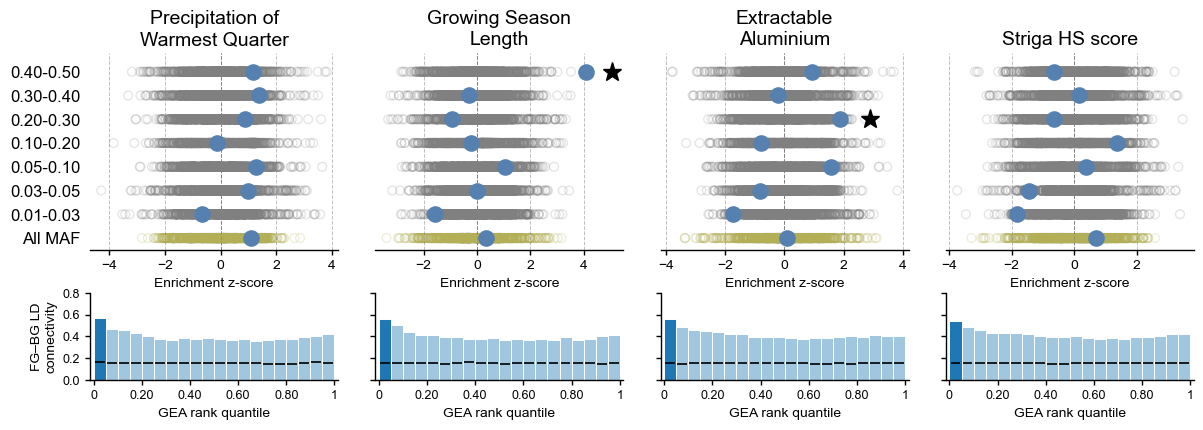

In [38]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.01_0.03_cds_0.01', '0.01-0.03'],
    ['maf_0.03_0.05_cds_0.01', '0.03-0.05'],
    ['maf_0.05_0.1_cds_0.01', '0.05-0.10'],
    ['maf_0.1_0.2_cds_0.01', '0.10-0.20'],
    ['maf_0.2_0.3_cds_0.01', '0.20-0.30'],
    ['maf_0.3_0.4_cds_0.01', '0.30-0.40'],
    ['maf_0.4_0.5_cds_0.01', '0.40-0.50']
]

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.3.3 putative_LoF_vs_CDS

In [39]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "putative_LoF_vs_CDS"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: putative_LoF_vs_CDS
Using dataset: cds
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: `putative_LoF_cds_0.01`
  Background set: cds
  MAF stratify: ['all', 'maf_0.01_0.03_cds_0.01', 'maf_0.03_0.05_cds_0.01', 'maf_0.05_0.1_cds_0.01', 'maf_0.1_0.2_cds_0.01', 'maf_0.2_0.3_cds_0.01', 'maf_0.3_0.4_cds_0.01', 'maf_0.4_0.5_cds_0.01']
Enrichment results already exist for contrast putative_LoF_vs_CDS, skipping.
LD overlap results already exist for contrast putative_LoF_vs_CDS. Skipping calculation.


Enrichment results for contrast: putative_LoF_vs_CDS


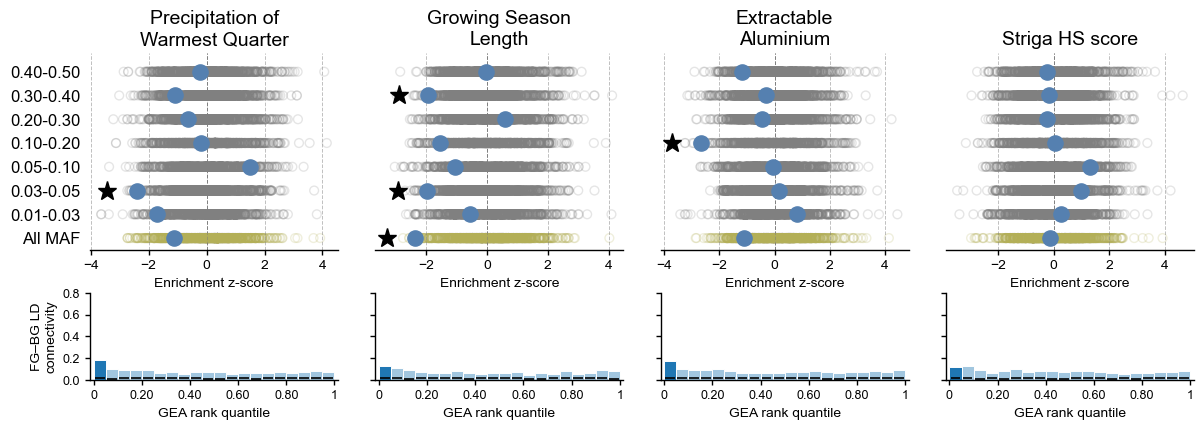

In [40]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.01_0.03_cds_0.01', '0.01-0.03'],
    ['maf_0.03_0.05_cds_0.01', '0.03-0.05'],
    ['maf_0.05_0.1_cds_0.01', '0.05-0.10'],
    ['maf_0.1_0.2_cds_0.01', '0.10-0.20'],
    ['maf_0.2_0.3_cds_0.01', '0.20-0.30'],
    ['maf_0.3_0.4_cds_0.01', '0.30-0.40'],
    ['maf_0.4_0.5_cds_0.01', '0.40-0.50']
]

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.3.4 putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05

In [41]:
from src.enrich import site_contrast_runner

contrast_id = "putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
contrast['maf_stratify'] = ['all']
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

Running enrichment for contrast: putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05
Using dataset: cds
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: `putative_LoF_cds_0.01` & `maf_0.01_0.03_cds_0.01`
  Background set: `putative_LoF_cds_0.01` & `maf_0.03_0.05_cds_0.01`
  MAF stratify: ['all']
Enrichment results already exist for contrast putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05, skipping.


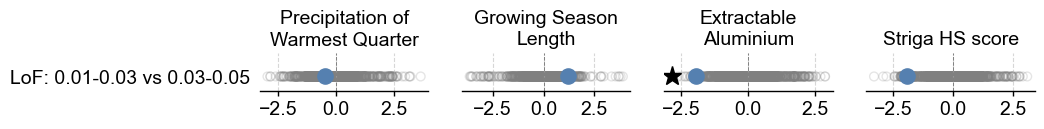

In [42]:
from src.enrich import plot_set_enrichment

set_label_map = [
    ['putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05', 'LoF: 0.01-0.03 vs 0.03-0.05'],
]

set_results_json = {}
for contrast_id, results_json_file in [("putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05", results_json_file)]:
    with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
        results_json = json.load(f)
    set_results_json[contrast_id] = results_json

plot_set_enrichment(set_results_json, env_id_list, env_metadata_df, set_label_map, significance_threshold=0.05)

### 2.4 riboSNitches

riboSNitch_vs_gene_body

In [43]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "riboSNitch_vs_gene_body"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: riboSNitch_vs_gene_body
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: riboSNitch & gene_body
  Background set: gene_body
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast riboSNitch_vs_gene_body, skipping.
LD overlap results already exist for contrast riboSNitch_vs_gene_body. Skipping calculation.


Enrichment results for contrast: riboSNitch_vs_gene_body


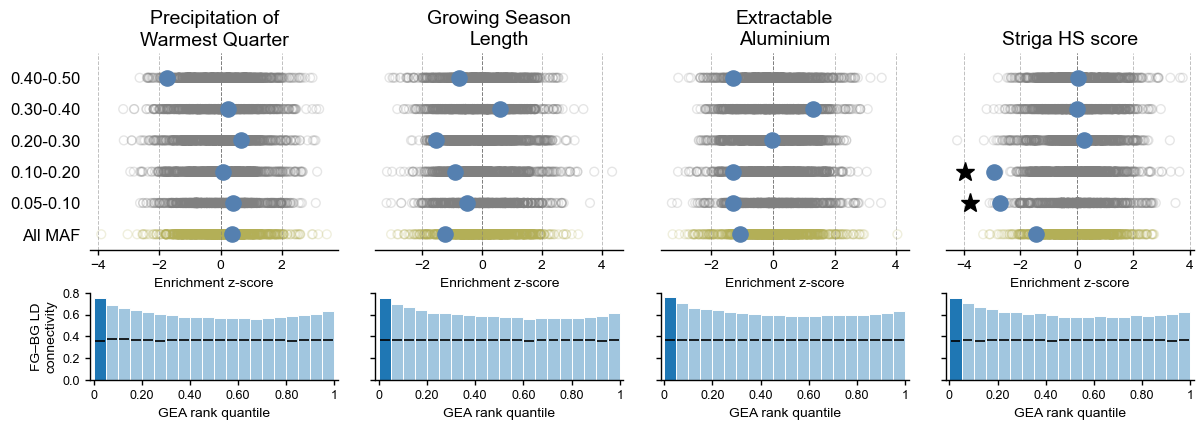

In [44]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

## 3. Epigenomic features

### 3.1 ACR_vs_genome

In [45]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "ACR_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: ACR_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: ACR
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast ACR_vs_genome, skipping.
LD overlap results already exist for contrast ACR_vs_genome. Skipping calculation.


Enrichment results for contrast: ACR_vs_genome


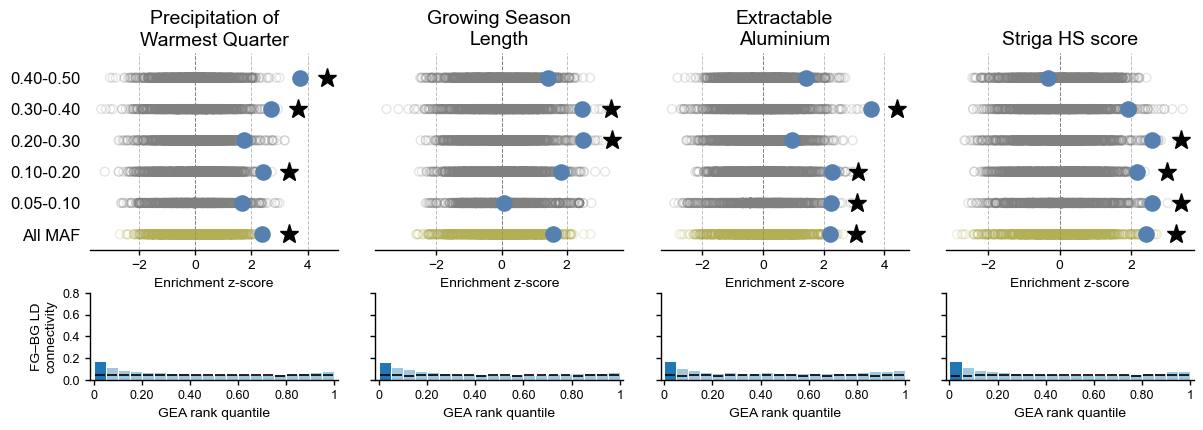

In [46]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 3.2 UMR_vs_genome

In [47]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "UMR_vs_genome"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: UMR_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: UMR
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast UMR_vs_genome, skipping.
LD overlap results already exist for contrast UMR_vs_genome. Skipping calculation.


Enrichment results for contrast: UMR_vs_genome


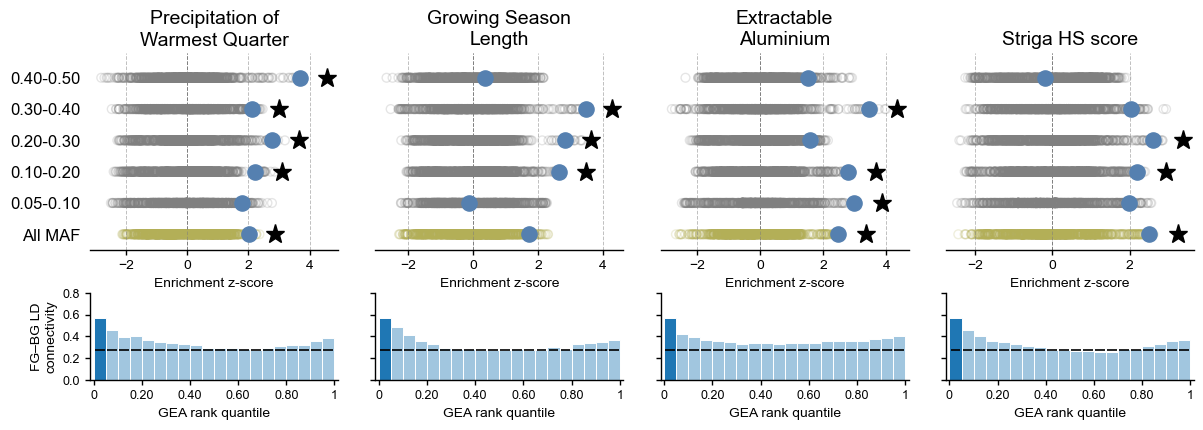

In [48]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

## 4. Genic proximal and distal

### 4.1 proximal_TE_vs_proximal

In [49]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "proximal_TE_vs_proximal"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: proximal_TE_vs_proximal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: genic_proximal & TE
  Background set: genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast proximal_TE_vs_proximal, skipping.
LD overlap results already exist for contrast proximal_TE_vs_proximal. Skipping calculation.


Enrichment results for contrast: proximal_TE_vs_proximal


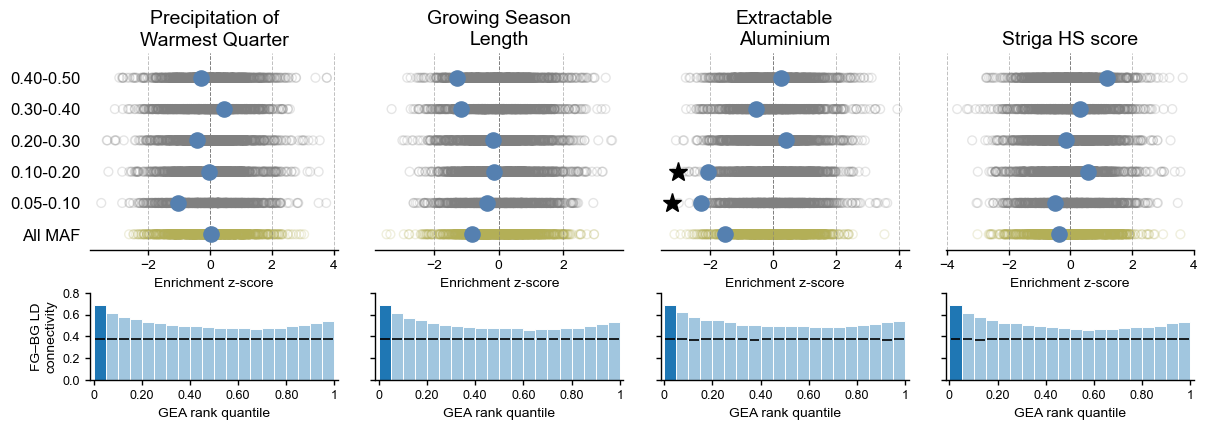

In [50]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 4.2 distal_TE_vs_distal

In [51]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "distal_TE_vs_distal"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: distal_TE_vs_distal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: (genome - genic_proximal) & TE
  Background set: genome - genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast distal_TE_vs_distal, skipping.
LD overlap results already exist for contrast distal_TE_vs_distal. Skipping calculation.


Enrichment results for contrast: distal_TE_vs_distal


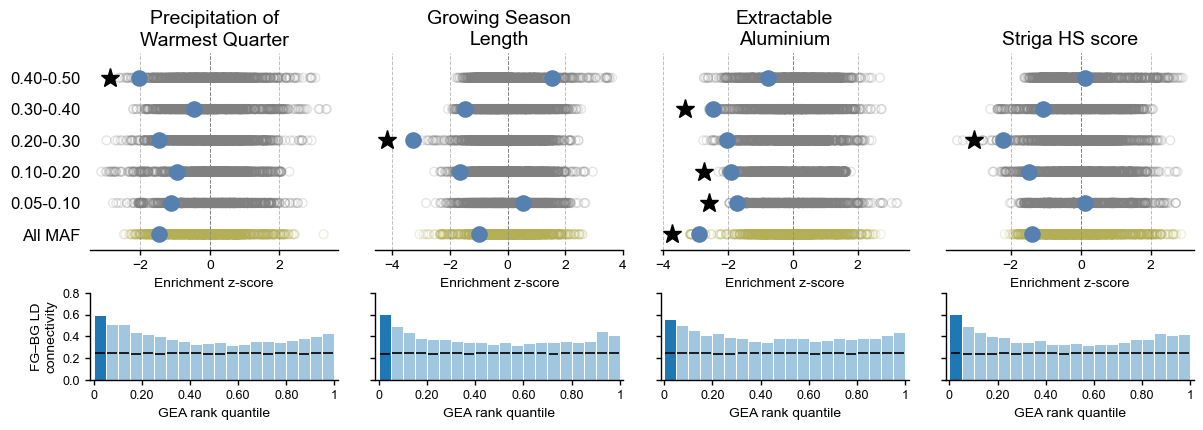

In [52]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 4.3 proximal_ACR_vs_proximal

In [53]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "proximal_ACR_vs_proximal"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: proximal_ACR_vs_proximal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: ACR & genic_proximal
  Background set: genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast proximal_ACR_vs_proximal, skipping.
LD overlap results already exist for contrast proximal_ACR_vs_proximal. Skipping calculation.


Enrichment results for contrast: proximal_ACR_vs_proximal


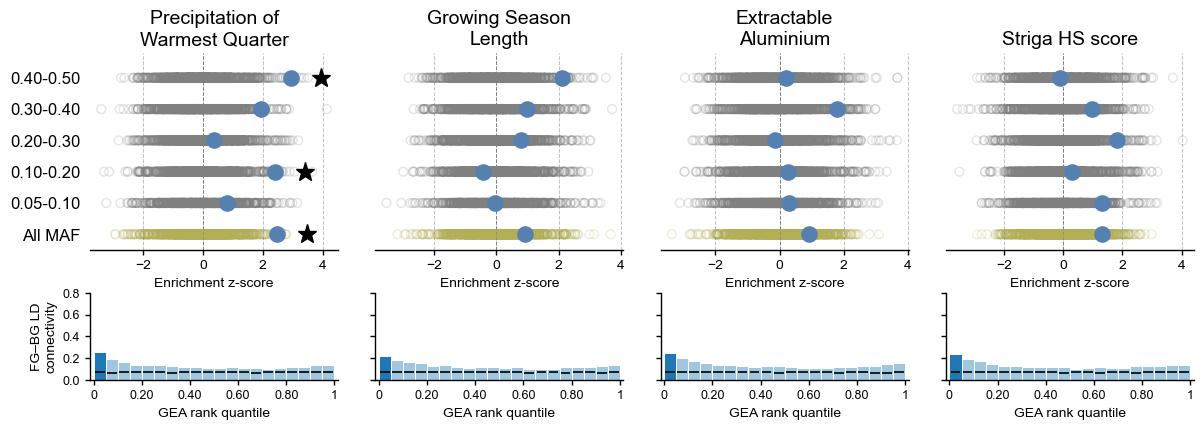

In [54]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 4.4 distal_ACR_vs_distal

In [55]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "distal_ACR_vs_distal"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: distal_ACR_vs_distal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: (genome - genic_proximal) & ACR
  Background set: genome - genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast distal_ACR_vs_distal, skipping.
LD overlap results already exist for contrast distal_ACR_vs_distal. Skipping calculation.


Enrichment results for contrast: distal_ACR_vs_distal


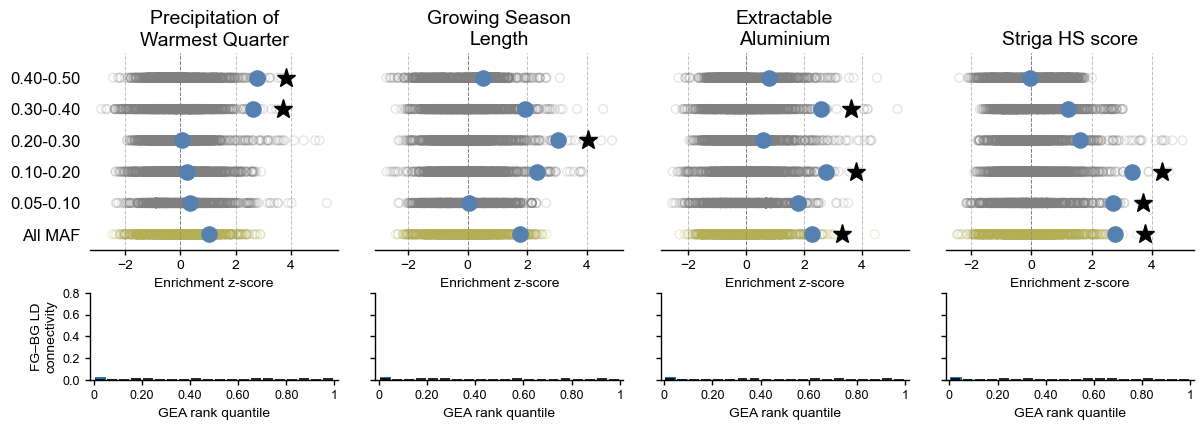

In [56]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 4.5 proximal_UMR_vs_proximal

In [57]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "proximal_UMR_vs_proximal"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: proximal_UMR_vs_proximal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: UMR & genic_proximal
  Background set: genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast proximal_UMR_vs_proximal, skipping.
LD overlap results already exist for contrast proximal_UMR_vs_proximal. Skipping calculation.


Enrichment results for contrast: proximal_UMR_vs_proximal


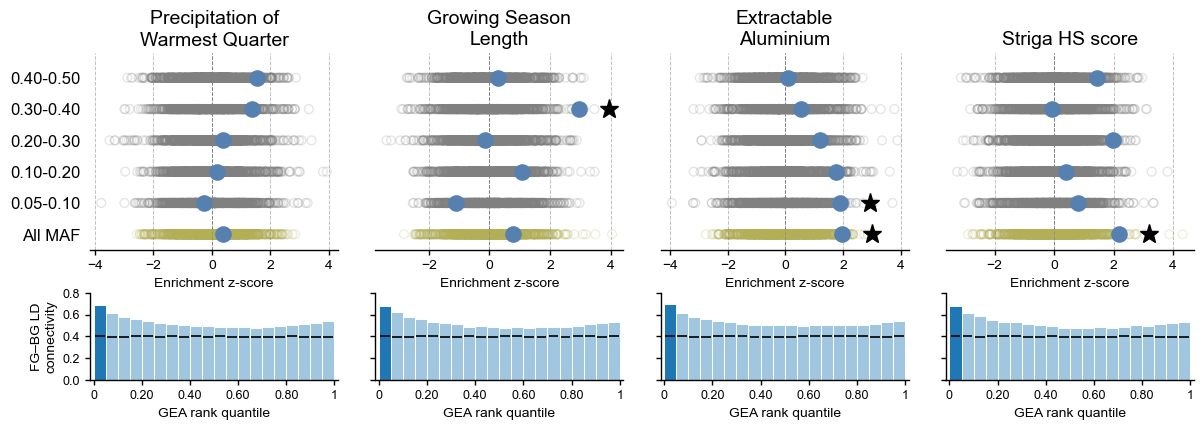

In [58]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 4.6 distal_UMR_vs_distal

In [59]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "distal_UMR_vs_distal"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: distal_UMR_vs_distal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: (genome - genic_proximal) & UMR
  Background set: genome - genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast distal_UMR_vs_distal, skipping.
LD overlap results already exist for contrast distal_UMR_vs_distal. Skipping calculation.


Enrichment results for contrast: distal_UMR_vs_distal


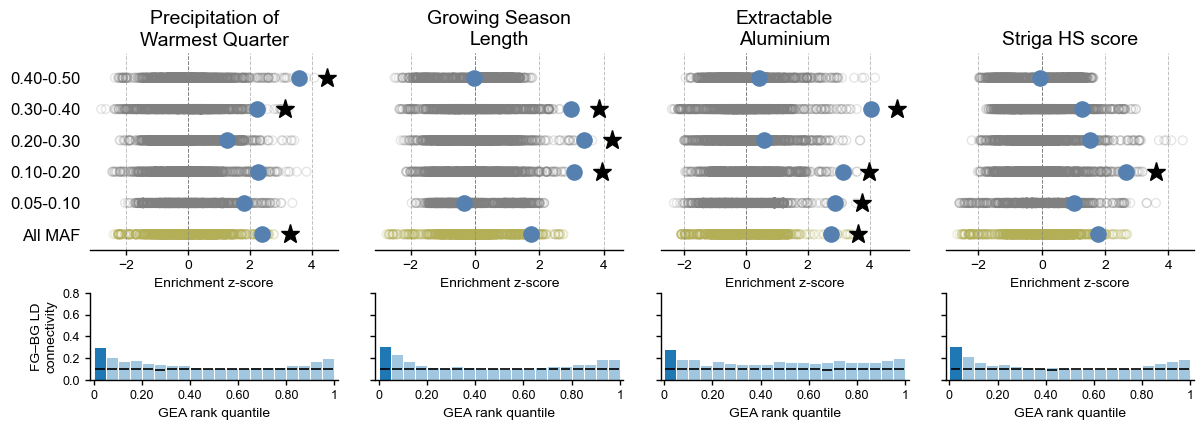

In [60]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 4.7 proximal_ACR_not_TE_vs_proximal_TE_not_ACR

In [61]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "proximal_ACR_not_TE_vs_proximal_TE_not_ACR"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: proximal_ACR_not_TE_vs_proximal_TE_not_ACR
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: (ACR & genic_proximal) - TE
  Background set: (TE & genic_proximal) - ACR
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast proximal_ACR_not_TE_vs_proximal_TE_not_ACR, skipping.
LD overlap results already exist for contrast proximal_ACR_not_TE_vs_proximal_TE_not_ACR. Skipping calculation.


Enrichment results for contrast: proximal_ACR_not_TE_vs_proximal_TE_not_ACR


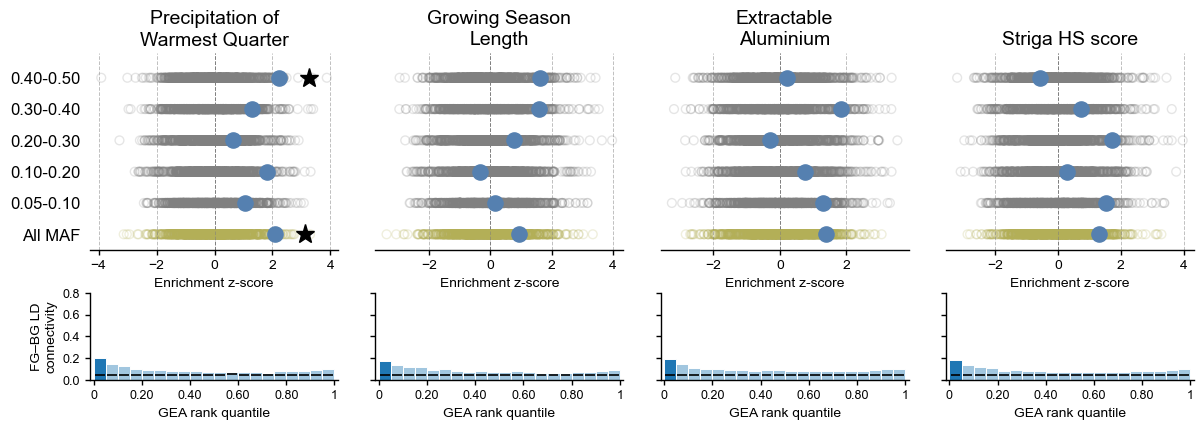

In [62]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

## 5. Evolutionary conservation & Population genetics

### 5.1 Nucleotide diversity (π)

#### 5.1.1 low_pi

In [63]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "low_pi"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: low_pi
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: low_pi & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast low_pi, skipping.
LD overlap results already exist for contrast low_pi. Skipping calculation.


Enrichment results for contrast: low_pi


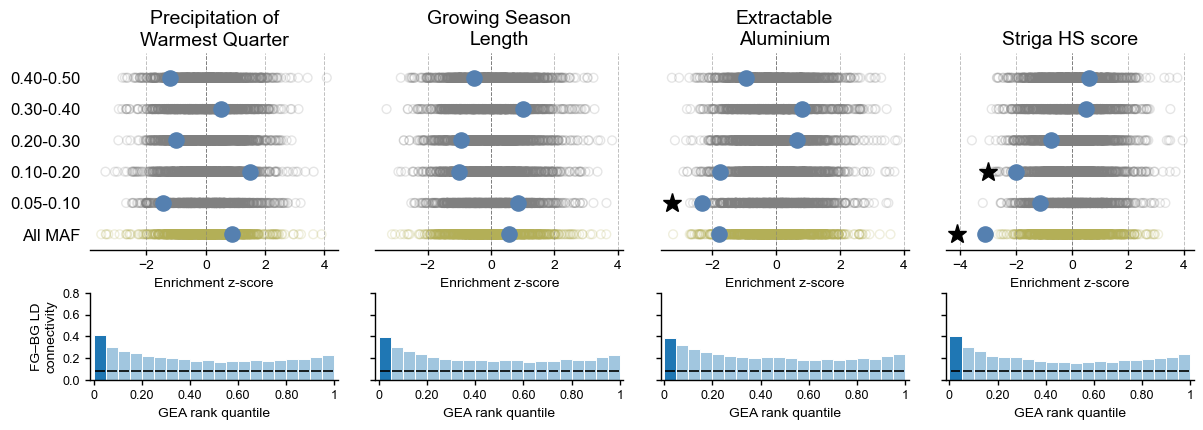

In [64]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 5.1.2 med_pi

In [65]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "med_pi"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: med_pi
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: med_pi & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast med_pi, skipping.
LD overlap results already exist for contrast med_pi. Skipping calculation.


Enrichment results for contrast: med_pi


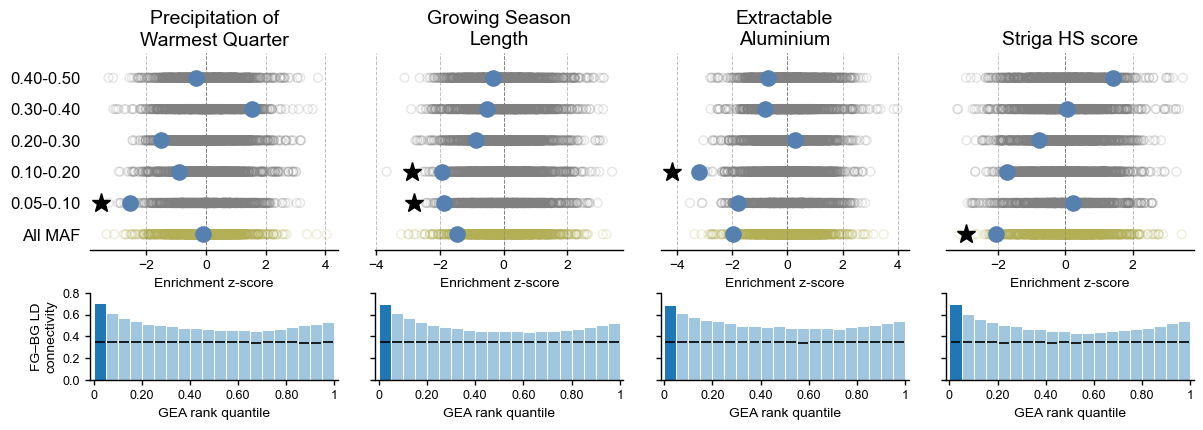

In [66]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 5.1.3 high_pi

In [67]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "high_pi"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: high_pi
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: high_pi & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Enrichment results already exist for contrast high_pi, skipping.
LD overlap results already exist for contrast high_pi. Skipping calculation.


Enrichment results for contrast: high_pi


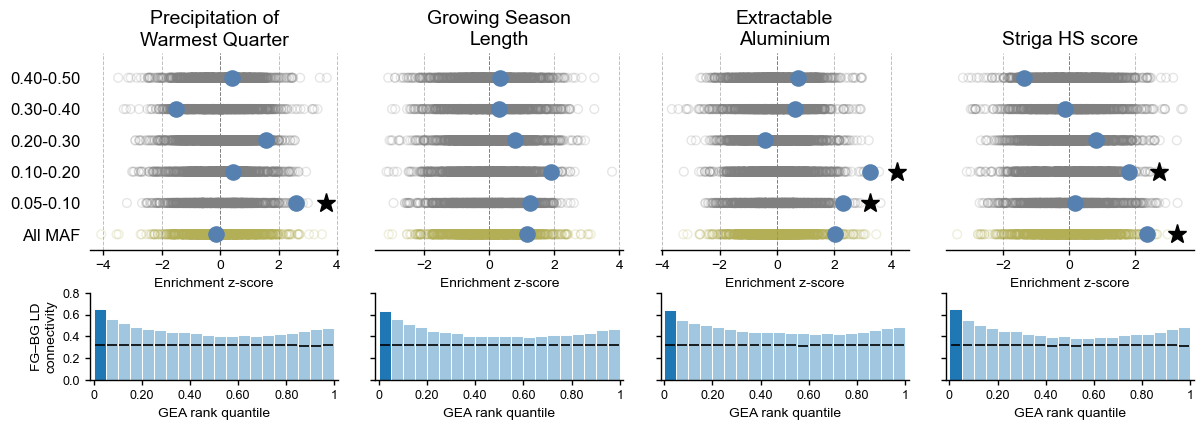

In [68]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 5.2 Minor allele frequency (MAF)

In [69]:
from src.enrich import site_contrast_runner

permutations = 1000
top_percent = 0.05
pool_num = 40

contrast_id = "maf_0.05_0.1"
contrast = contrasts_settings[contrast_id]
contrast['maf_stratify'] = ['all']
maf_0_05_0_1_results_json_file = site_contrast_runner(contrast_id, contrast, datasets[contrast["dataset"]], env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)

contrast_id = "maf_0.1_0.2"
contrast = contrasts_settings[contrast_id]
contrast['maf_stratify'] = ['all']
maf_0_1_0_2_results_json_file = site_contrast_runner(contrast_id, contrast, datasets[contrast["dataset"]], env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)

contrast_id = "maf_0.2_0.3"
contrast = contrasts_settings[contrast_id]
contrast['maf_stratify'] = ['all']
maf_0_2_0_3_results_json_file = site_contrast_runner(contrast_id, contrast, datasets[contrast["dataset"]], env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)

contrast_id = "maf_0.3_0.4"
contrast = contrasts_settings[contrast_id]
contrast['maf_stratify'] = ['all']
maf_0_3_0_4_results_json_file = site_contrast_runner(contrast_id, contrast, datasets[contrast["dataset"]], env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)

contrast_id = "maf_0.4_0.5"
contrast = contrasts_settings[contrast_id]
contrast['maf_stratify'] = ['all']
maf_0_4_0_5_results_json_file = site_contrast_runner(contrast_id, contrast, datasets[contrast["dataset"]], env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)

Enrichment results already exist for contrast maf_0.05_0.1, skipping.
Enrichment results already exist for contrast maf_0.1_0.2, skipping.
Enrichment results already exist for contrast maf_0.2_0.3, skipping.
Enrichment results already exist for contrast maf_0.3_0.4, skipping.
Enrichment results already exist for contrast maf_0.4_0.5, skipping.


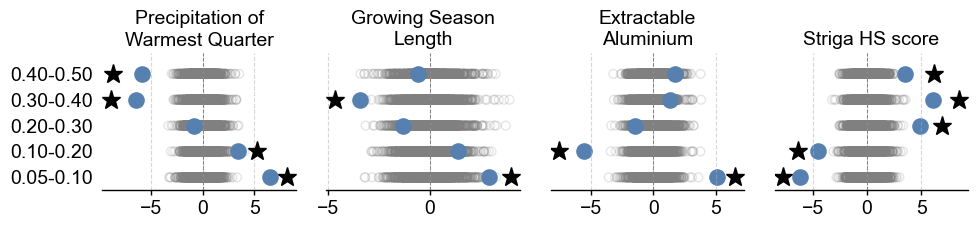

In [70]:
from src.enrich import plot_set_enrichment

set_label_map = [
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50']
]

set_results_json = {}
for contrast_id, results_json_file in [("maf_0.05_0.1", maf_0_05_0_1_results_json_file), ("maf_0.1_0.2", maf_0_1_0_2_results_json_file), ("maf_0.2_0.3", maf_0_2_0_3_results_json_file), ("maf_0.3_0.4", maf_0_3_0_4_results_json_file), ("maf_0.4_0.5", maf_0_4_0_5_results_json_file)]:
    with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
        results_json = json.load(f)
    set_results_json[contrast_id] = results_json

plot_set_enrichment(set_results_json, env_id_list, env_metadata_df, set_label_map, significance_threshold=0.05)

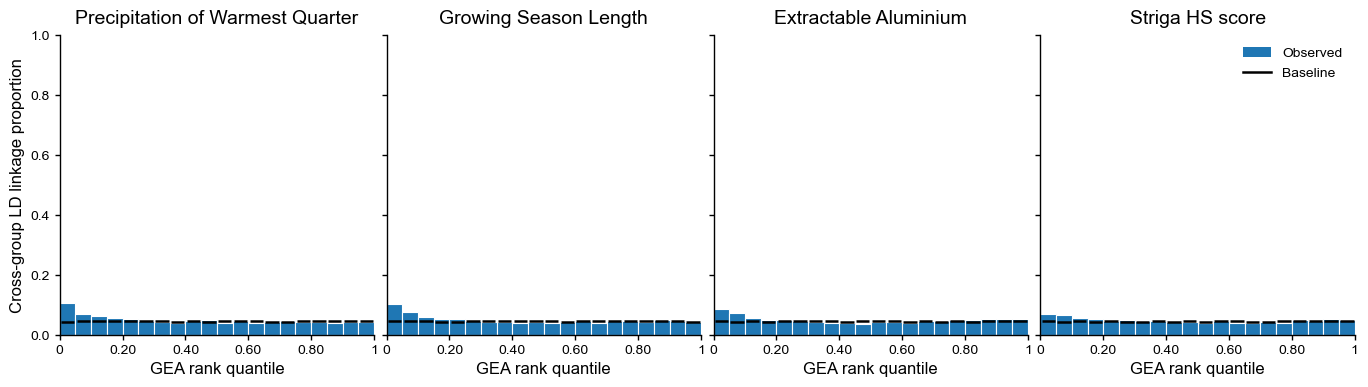

In [72]:
from src.ld import plot_overlap_by_quantile

contrast_id = "maf_0.05_0.1"
contrast = contrasts_settings[contrast_id]
context_df = datasets[contrast["dataset"]]

overlap_results_file = os.path.join(enrich_dir, f"{contrast_id}_overlap_results.pkl")
if os.path.exists(overlap_results_file):
    with open(overlap_results_file, "rb") as f:
        overlap_results = pickle.load(f)
else:
    overlap_results = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], bin_width=0.05, min_R2=0.5, random_seed=42)
    with open(overlap_results_file, "wb") as f:
        pickle.dump(overlap_results, f)

fig, axs = plot_overlap_by_quantile(overlap_results, env_id_list, env_metadata_df)        

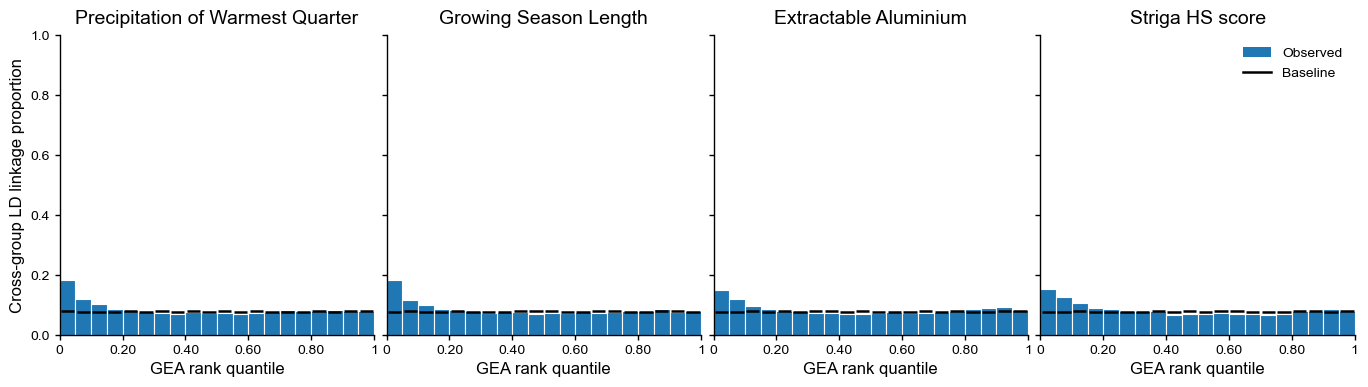

In [73]:
contrast_id = "maf_0.1_0.2"
contrast = contrasts_settings[contrast_id]
context_df = datasets[contrast["dataset"]]

overlap_results_file = os.path.join(enrich_dir, f"{contrast_id}_overlap_results.pkl")
if os.path.exists(overlap_results_file):
    with open(overlap_results_file, "rb") as f:
        overlap_results = pickle.load(f)
else:
    overlap_results = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], bin_width=0.05, min_R2=0.5, random_seed=42)
    with open(overlap_results_file, "wb") as f:
        pickle.dump(overlap_results, f)

fig, axs = plot_overlap_by_quantile(overlap_results, env_id_list, env_metadata_df)        

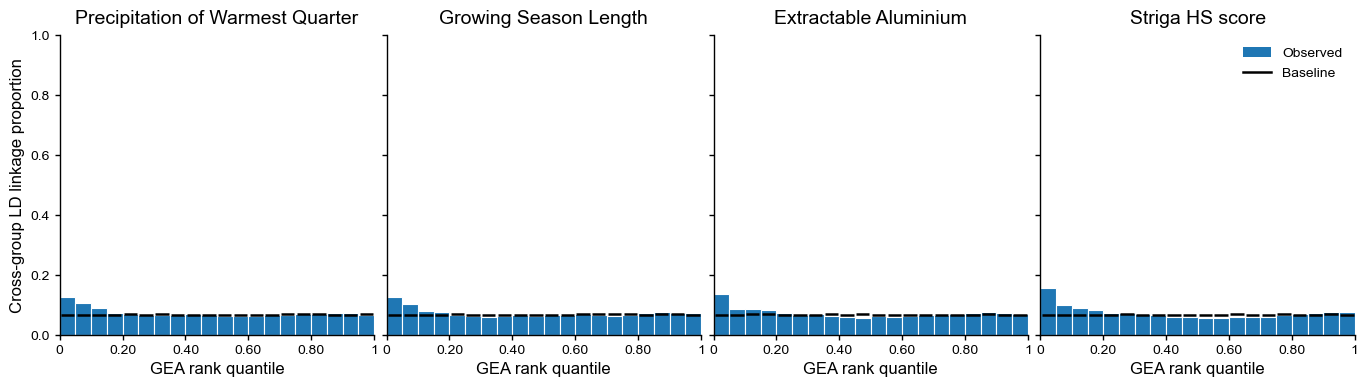

In [74]:
contrast_id = "maf_0.2_0.3"
contrast = contrasts_settings[contrast_id]
context_df = datasets[contrast["dataset"]]

overlap_results_file = os.path.join(enrich_dir, f"{contrast_id}_overlap_results.pkl")
if os.path.exists(overlap_results_file):
    with open(overlap_results_file, "rb") as f:
        overlap_results = pickle.load(f)
else:
    overlap_results = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], bin_width=0.05, min_R2=0.5, random_seed=42)
    with open(overlap_results_file, "wb") as f:
        pickle.dump(overlap_results, f)

fig, axs = plot_overlap_by_quantile(overlap_results, env_id_list, env_metadata_df)        

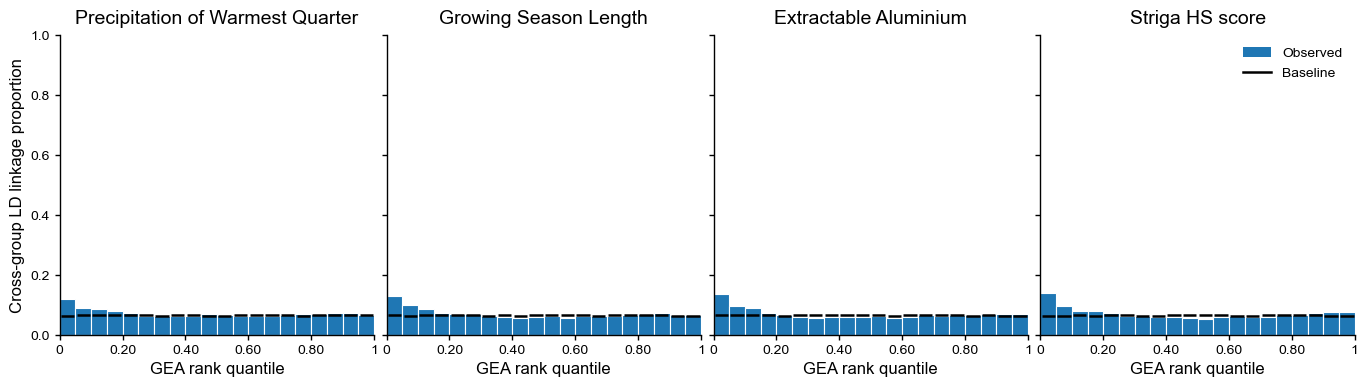

In [75]:
contrast_id = "maf_0.3_0.4"
contrast = contrasts_settings[contrast_id]
context_df = datasets[contrast["dataset"]]

overlap_results_file = os.path.join(enrich_dir, f"{contrast_id}_overlap_results.pkl")
if os.path.exists(overlap_results_file):
    with open(overlap_results_file, "rb") as f:
        overlap_results = pickle.load(f)
else:
    overlap_results = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], bin_width=0.05, min_R2=0.5, random_seed=42)
    with open(overlap_results_file, "wb") as f:
        pickle.dump(overlap_results, f)

fig, axs = plot_overlap_by_quantile(overlap_results, env_id_list, env_metadata_df)        

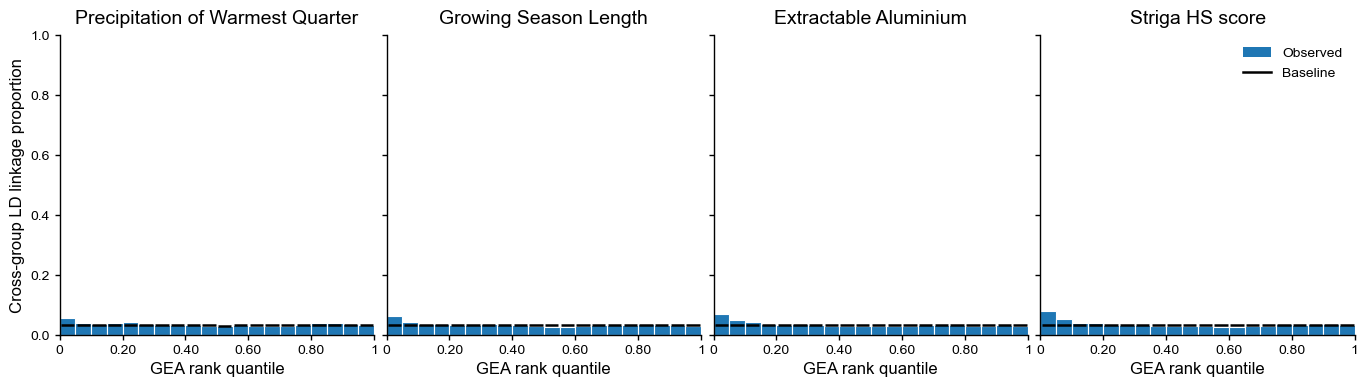

In [76]:
contrast_id = "maf_0.4_0.5"
contrast = contrasts_settings[contrast_id]
context_df = datasets[contrast["dataset"]]

overlap_results_file = os.path.join(enrich_dir, f"{contrast_id}_overlap_results.pkl")
if os.path.exists(overlap_results_file):
    with open(overlap_results_file, "rb") as f:
        overlap_results = pickle.load(f)
else:
    overlap_results = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], bin_width=0.05, min_R2=0.5, random_seed=42)
    with open(overlap_results_file, "wb") as f:
        pickle.dump(overlap_results, f)

fig, axs = plot_overlap_by_quantile(overlap_results, env_id_list, env_metadata_df)        

### 5.3 Phylogenetic conservation (PhyloP)

#### 5.3.1 non_CEs

In [5]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "non_CEs"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: non_CEs
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: non_CEs & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 20.5s | 48.73/s | ETA 0.0s
1000 permutations with pool_num=40: 20.83 s (48.00 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.6s | 103.86/s | ETA 0.0s
1000 permutations with pool_num=40: 9.96 s (100.41 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 11.1s | 90.21/s | ETA 0.0s
1000 permutations with pool_num=40: 11.44 s (87.44 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 7.7s | 130.70/s | ETA 0.0s
1000 permutations with pool_num=40: 7.97 s (125.45 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 7.3s | 136.48/s | ETA 0.0s
1000 permutations with pool_num=40: 7.66 s (130.60 permutations/s)
Permutations: 1000/1000 (1

Enrichment results for contrast: non_CEs


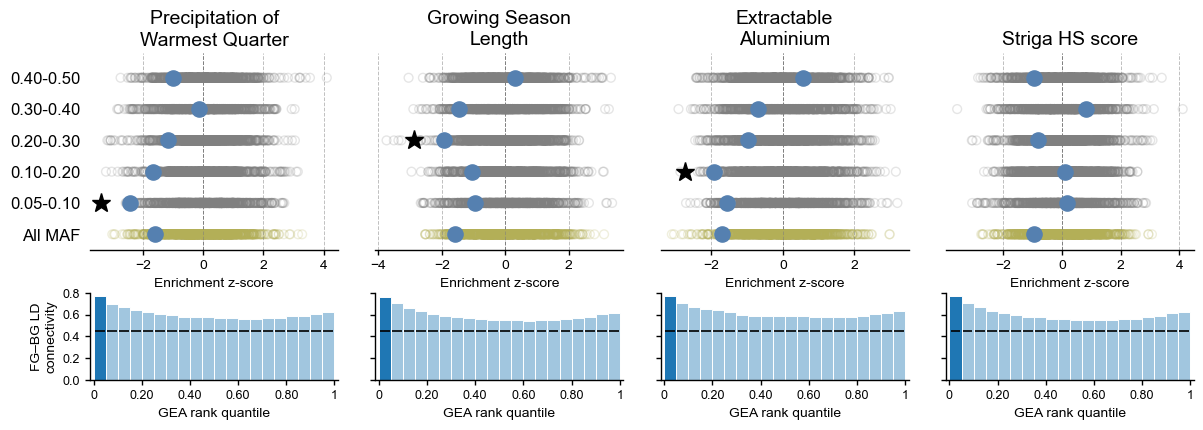

In [6]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 5.3.2 conserved_sites

In [7]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "conserved_sites"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: conserved_sites
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: conserved_sites & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 20.3s | 49.16/s | ETA 0.0s
1000 permutations with pool_num=40: 20.78 s (48.11 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 10.0s | 100.33/s | ETA 0.0s
1000 permutations with pool_num=40: 10.32 s (96.89 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 10.0s | 99.56/s | ETA 0.0s
1000 permutations with pool_num=40: 10.38 s (96.34 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.2s | 108.22/s | ETA 0.0s
1000 permutations with pool_num=40: 9.57 s (104.50 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 7.9s | 126.31/s | ETA 0.0s
1000 permutations with pool_num=40: 8.23 s (121.44 permutations/s)
Permutati

Enrichment results for contrast: conserved_sites


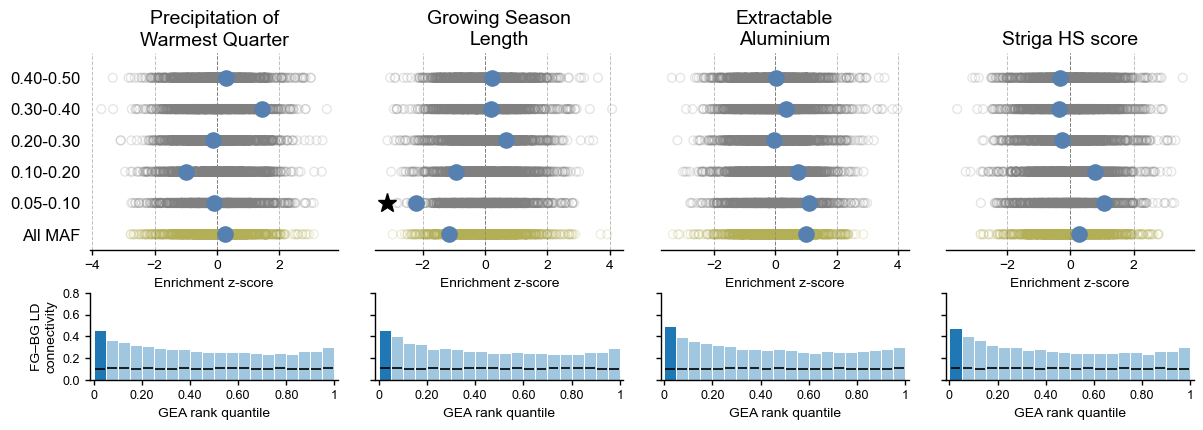

In [8]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 5.3.3 neutral_sites

In [9]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "neutral_sites"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: neutral_sites
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: neutral_sites & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 24.3s | 41.12/s | ETA 0.0s
1000 permutations with pool_num=40: 24.79 s (40.34 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.1s | 110.28/s | ETA 0.0s
1000 permutations with pool_num=40: 9.39 s (106.47 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 9.5s | 105.32/s | ETA 0.0s
1000 permutations with pool_num=40: 9.83 s (101.77 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 7.7s | 129.47/s | ETA 0.0s
1000 permutations with pool_num=40: 8.04 s (124.41 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 7.3s | 137.35/s | ETA 0.0s
1000 permutations with pool_num=40: 7.61 s (131.42 permutations/s)
Permutations: 

Enrichment results for contrast: neutral_sites


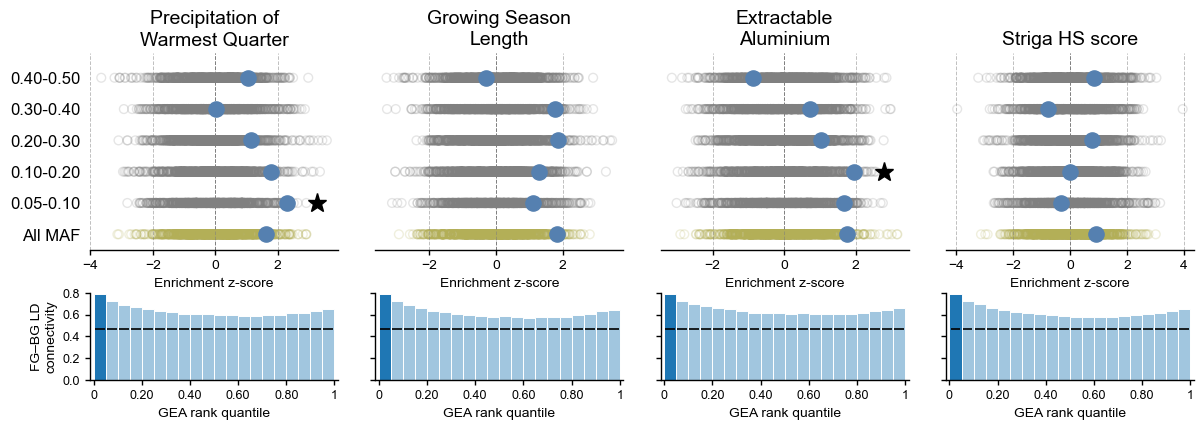

In [10]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 5.3.4 accelerated_sites

In [11]:
from src.enrich import site_contrast_runner
from src.ld import calculate_contrast_ld_overlap
import pickle

contrast_id = "accelerated_sites"
permutations = 1000
top_percent = 0.05
pool_num = 40
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: {pool_num}")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")
context_df = datasets[contrast["dataset"]]
results_json_file = site_contrast_runner(contrast_id, contrast, context_df, env_id_list, enrich_dir, permutations=permutations, top_percent=top_percent, pool_num=pool_num)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(contrast_id, contrast, context_df, env_id_list, ld_dict[contrast["dataset"]], enrich_dir, bin_width=0.05, min_R2=0.5, random_seed=42)
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)
with open(ld_overlap_pkl_file, 'rb') as f:
    ld_overlap_dict = pickle.load(f)

Running enrichment for contrast: accelerated_sites
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 40
  Foreground set: accelerated_sites & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Permutations: 1000/1000 (100.0%) | elapsed 21.5s | 46.59/s | ETA 0.0s
1000 permutations with pool_num=40: 21.88 s (45.69 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 10.0s | 100.19/s | ETA 0.0s
1000 permutations with pool_num=40: 10.26 s (97.44 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 11.2s | 89.51/s | ETA 0.0s
1000 permutations with pool_num=40: 11.48 s (87.10 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 8.3s | 120.03/s | ETA 0.0s
1000 permutations with pool_num=40: 8.65 s (115.61 permutations/s)
Permutations: 1000/1000 (100.0%) | elapsed 8.2s | 121.29/s | ETA 0.0s
1000 permutations with pool_num=40: 8.55 s (117.00 permutations/s)
Permu

Enrichment results for contrast: accelerated_sites


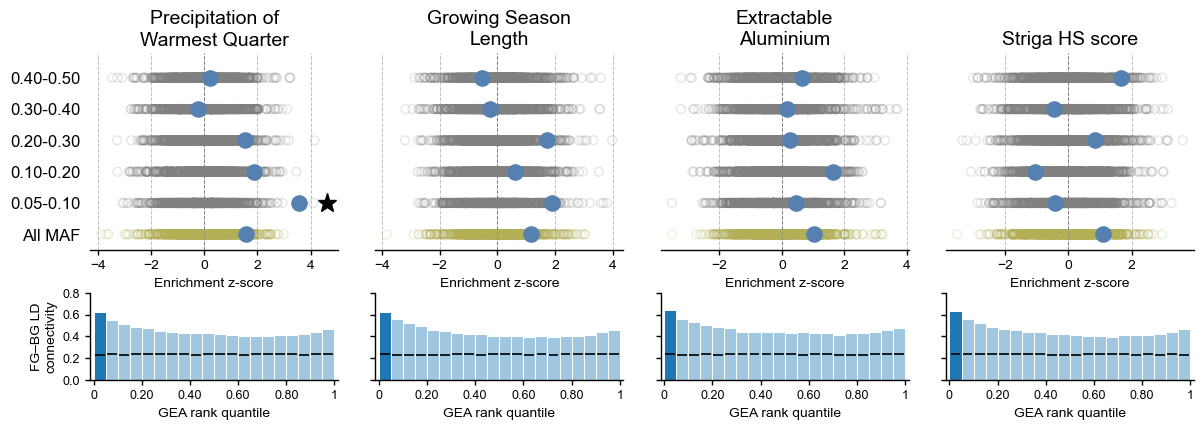

In [12]:
from src.enrich import plot_enrichment_and_overlap

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]
print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment_and_overlap.pdf")
fig, axs = plot_enrichment_and_overlap(results_json, ld_overlap_dict, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

## 6. Flowering time genes

In [11]:
from src.enrich import gene_contrast_runner

permutations = 1000
top_percent = 0.05

contrast_id = "flowering_time_genes"
contrast = contrasts_settings[contrast_id]
results_json_file = gene_contrast_runner(contrast_id, contrast, datasets[contrast["dataset"]], env_id_list, enrich_dir, permutations=1000, top_percent=0.05)

Enrichment results already exist for contrast flowering_time_genes, skipping.


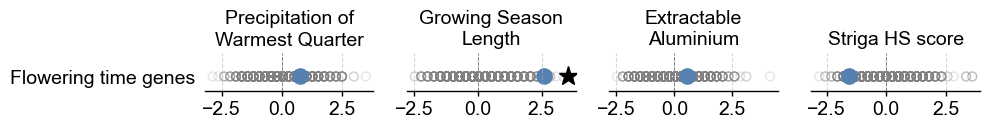

In [12]:
from src.enrich import plot_set_enrichment

set_label_map = [
    ['flowering_time_genes_vs_all_genes', 'Flowering time genes']
]

set_results_json = {}
for contrast_id, results_json_file in [("flowering_time_genes_vs_all_genes", results_json_file)]:
    with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
        results_json = json.load(f)
    set_results_json[contrast_id] = results_json

save_path = os.path.join(enrich_dir, f"{contrast_id}.enrichment.pdf")
fig, axs = plot_set_enrichment(set_results_json, env_id_list, env_metadata_df, set_label_map, significance_threshold=0.05)
fig.savefig(save_path, bbox_inches='tight')

## 7. Gene Expression

In [18]:
from src.enrich import gene_contrast_runner

permutations = 1000
top_percent = 0.05

set_label_map = [
    ['stably_expressed_genes', 'Genes with stable expr.'],
    ['high_variance_genes', 'Genes with high var. expr.'],
    ['no_expression_genes', 'Genes with no detected expr.']
]

results_json_files = {}
for contrast_id in ["no_expression_genes", "high_variance_genes", "stably_expressed_genes"]:
    contrast = contrasts_settings[contrast_id]
    results_json_file = gene_contrast_runner(contrast_id, contrast, datasets[contrast["dataset"]], env_id_list, enrich_dir, permutations=1000, top_percent=0.05)
    results_json_files[contrast_id] = results_json_file

Enrichment results already exist for contrast no_expression_genes, skipping.
Enrichment results already exist for contrast high_variance_genes, skipping.
Enrichment results already exist for contrast stably_expressed_genes, skipping.


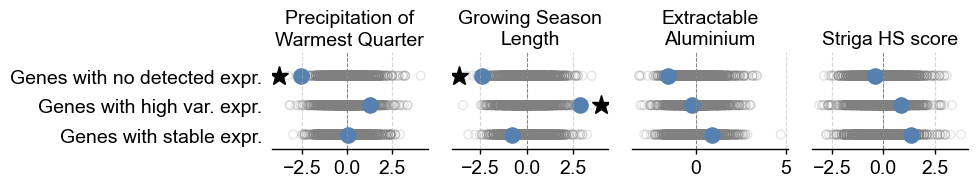

In [19]:
from src.enrich import plot_set_enrichment

set_results_json = {}
for contrast_id, results_json_file in results_json_files.items():
    with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
        results_json = json.load(f)
    set_results_json[contrast_id] = results_json

set_id = "gene_expression"
save_path = os.path.join(enrich_dir, f"{set_id}.enrichment.pdf")
fig, axs = plot_set_enrichment(set_results_json, env_id_list, env_metadata_df, set_label_map, significance_threshold=0.05, height_per_set=0.7)
fig.savefig(save_path, bbox_inches='tight')

## 8. Gene Regulatory Network

In [20]:
from src.enrich import gene_contrast_runner

permutations = 1000
top_percent = 0.05

set_label_map = [
    ['module_hub_genes', 'Module hubs'],
    ['module_genes', 'Module genes'],
    ['non_module_genes', 'Non-module genes'],
]

results_json_files = {}
for contrast_id, _ in set_label_map:
    contrast = contrasts_settings[contrast_id]
    results_json_file = gene_contrast_runner(contrast_id, contrast, datasets[contrast["dataset"]], env_id_list, enrich_dir, permutations=1000, top_percent=0.05)
    results_json_files[contrast_id] = results_json_file

Enrichment results already exist for contrast module_hub_genes, skipping.
Enrichment results already exist for contrast module_genes, skipping.
Enrichment results already exist for contrast non_module_genes, skipping.


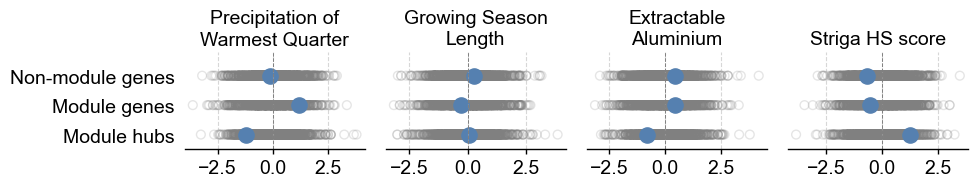

In [21]:
from src.enrich import plot_set_enrichment

set_results_json = {}
for contrast_id, results_json_file in results_json_files.items():
    with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
        results_json = json.load(f)
    set_results_json[contrast_id] = results_json

set_id = "gene_regulatory_network"
save_path = os.path.join(enrich_dir, f"{set_id}.enrichment.pdf")
fig, axs = plot_set_enrichment(set_results_json, env_id_list, env_metadata_df, set_label_map, significance_threshold=0.05, height_per_set=0.7)
fig.savefig(save_path, bbox_inches='tight')

## 9. Gene copy redundancy

In [24]:
from src.enrich import gene_contrast_runner

permutations = 1000
top_percent = 0.05

set_label_map = [
    ['single_copy_genes', 'Single-copy genes'],
    ['multi_copy_genes', 'Multi-copy genes'],
    ['orphan_genes', 'Orphan genes'],    
]

results_json_files = {}
for contrast_id, _ in set_label_map:
    contrast = contrasts_settings[contrast_id]
    results_json_file = gene_contrast_runner(contrast_id, contrast, datasets[contrast["dataset"]], env_id_list, enrich_dir, permutations=1000, top_percent=0.05)
    results_json_files[contrast_id] = results_json_file

Enrichment results already exist for contrast single_copy_genes, skipping.
Enrichment results already exist for contrast multi_copy_genes, skipping.
Enrichment results already exist for contrast orphan_genes, skipping.


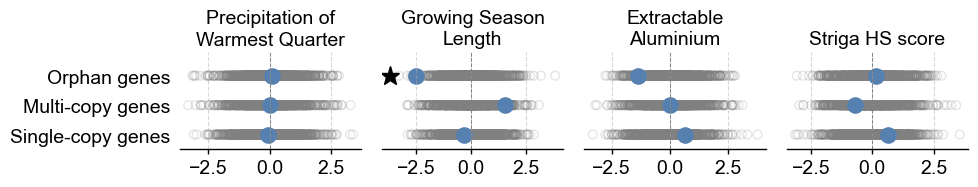

In [25]:
from src.enrich import plot_set_enrichment

set_results_json = {}
for contrast_id, results_json_file in results_json_files.items():
    with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
        results_json = json.load(f)
    set_results_json[contrast_id] = results_json

set_id = "gene_regulatory_network"
save_path = os.path.join(enrich_dir, f"{set_id}.enrichment.pdf")
fig, axs = plot_set_enrichment(set_results_json, env_id_list, env_metadata_df, set_label_map, significance_threshold=0.05, height_per_set=0.7)
fig.savefig(save_path, bbox_inches='tight')

## 10. Recombination rate

In [26]:
from src.enrich import gene_contrast_runner

permutations = 1000
top_percent = 0.05

set_label_map = [
    ['high_recombination_genes', 'Genes in high recomb. regions'],
    ['med_recombination_genes', 'Genes in med. recomb. regions'],
    ['low_recombination_genes', 'Genes in low recomb. regions'],    
]

results_json_files = {}
for contrast_id, _ in set_label_map:
    contrast = contrasts_settings[contrast_id]
    results_json_file = gene_contrast_runner(contrast_id, contrast, datasets[contrast["dataset"]], env_id_list, enrich_dir, permutations=1000, top_percent=0.05)
    results_json_files[contrast_id] = results_json_file

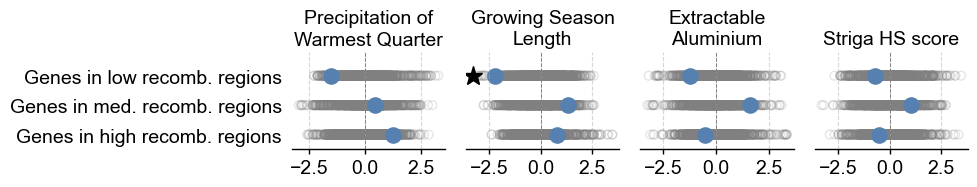

In [27]:
from src.enrich import plot_set_enrichment

set_results_json = {}
for contrast_id, results_json_file in results_json_files.items():
    with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
        results_json = json.load(f)
    set_results_json[contrast_id] = results_json

set_id = "gene_regulatory_network"
save_path = os.path.join(enrich_dir, f"{set_id}.enrichment.pdf")
fig, axs = plot_set_enrichment(set_results_json, env_id_list, env_metadata_df, set_label_map, significance_threshold=0.05, height_per_set=0.7)
fig.savefig(save_path, bbox_inches='tight')